In [20]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/AaronWanh/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

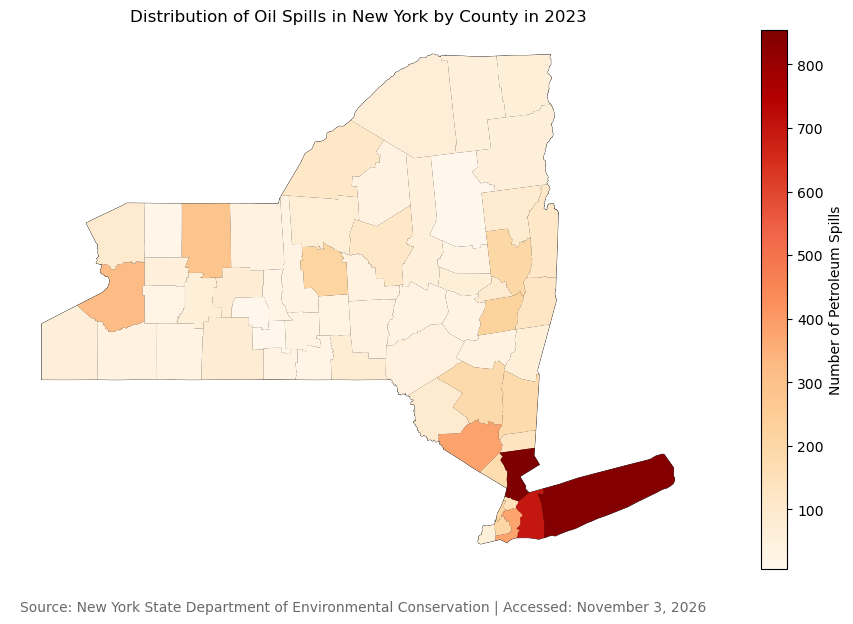

In [49]:
# FINAL CODE

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# read spills dataset
fp = os.path.join("data/Spill_Incidents_20261102.csv")
spills = gpd.read_file(fp)
# read U.S. counties dataset
fp = os.path.join("data/tl_2026_us_county/tl_2026_us_county.shp")
counties = gpd.read_file(fp)

# cleaning column names to be consistent and simple
spills.columns = spills.columns.str.lower().str.replace(" ", "_")
counties.columns = counties.columns.str.lower()

# change the data type of the spill date to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

# select only petroleum spills that occured in 2023
petr_23 = spills[(spills['spill_date'] >= '2023-01-01') & (spills['spill_date'] <= '2023-12-31') & (spills['material_family'] == 'Petroleum')]

# create a dataset that shows how many unique spills occurred in each county
# This will create pandas Series not a DataFrame. You need to reset the index back to integer indexing. 
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index(drop=False)
spills_per_county = spills_per_county.rename(columns = {'spill_number' : 'n_spills'})

ny_counties = counties[counties['statefp'] == '36']

# change the name of St Lawrence ot match the name in ny_counties
spills_per_county = spills_per_county.replace({'St Lawrence' : 'St. Lawrence'})

# rename the county column to match the column in spills_per_county
ny_counties = ny_counties.rename(columns = {'name' : 'county'})

# join spills_per_county and ny_counties
ny_spills = pd.merge(spills_per_county, ny_counties)

# add the number of spillls from Onondaga Indian Reservation to Onondaga
onon_indian_reserve = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].iloc[0]
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += onon_indian_reserve

# add the number of spillls from Tuscarora Indian Reservation to Niagara
tusc_indian_reserve = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].iloc[0]
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += tusc_indian_reserve

# convert ny_spills from pandas data series to a geodataframe
ny_spills = gpd.GeoDataFrame(
    ny_spills,
    geometry='geometry',
    crs=ny_counties.crs
)

fig, ax = plt.subplots(figsize = (14, 7))

# plot New York county boundaries 
ny_counties.plot(
    ax = ax,
    facecolor='lightgray',
    edgecolor='black',
    linewidth=0.5
)

# plot oil spills values 
ny_spills.plot(
    ax=ax,
    column='n_spills',
    cmap='OrRd',
    legend=True,
    legend_kwds = {'label' : "Number of Petroleum Spills"}
)
ax.set_title('Distribution of Oil Spills in New York by County in 2023')
ax.set_axis_off()

# add text that sources the dataset
fig.text(
    0.5, 0.05,
    'Source: New York State Department of Environmental Conservation | Accessed: November 3, 2026',
    ha='center',
    fontsize=10,
    color='dimgray'
)

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [3]:
# read spills dataset
fp = os.path.join("data/Spill_Incidents_20261102.csv")
spills = gpd.read_file(fp)

# read U.S. counties dataset
fp = os.path.join("data/tl_2026_us_county/tl_2026_us_county.shp")
counties = gpd.read_file(fp)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [4]:
#a. Check the dataframe's head
spills.head()
counties.head()


,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [5]:
#b. Check the data types of the columns
spills.dtypes


Spill Number               object
Program Facility Name      object
Street 1                   object
Street 2                   object
Locality                   object
County                     object
ZIP Code                   object
SWIS Code                  object
DEC Region                 object
Spill Date                 object
Received Date              object
Contributing Factor        object
Waterbody                  object
Source                     object
Close Date                 object
Material Name              object
Material Family            object
Quantity                   object
Units                      object
Recovered                  object
geometry                 geometry
dtype: object

In [6]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [7]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [8]:
# cleaning column names to be consistent and simple
spills.columns = spills.columns.str.lower().str.replace(" ", "_")

In [9]:
spills.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,...,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
0,0107132,MH 864,RT 119/MILLWOOD RD,,ELMSFORD,Westchester,,6000,3,10/10/2001,...,Unknown,,Unknown,10/15/2001,unknown material,Other,10,Gallons,0,None
1,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,08/21/2004,...,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,,0,None
2,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,08/21/2004,...,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0,None
3,0204667,POLE 16091,GRACE AVE/BURKE AVE,,BRONX,Bronx,,0301,2,08/02/2002,...,Equipment Failure,,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0,None
4,0210559,POLE ON,FERDALE LOMIS RD / RT 52,,LIBERTY,Sullivan,,5336,3,01/20/2003,...,Traffic Accident,,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6,None


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [10]:
# change the data type of the spill date to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
spills

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,...,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
0,0107132,MH 864,RT 119/MILLWOOD RD,,ELMSFORD,Westchester,,6000,3,2001-10-10,...,Unknown,,Unknown,10/15/2001,unknown material,Other,10,Gallons,0,None
1,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,2004-08-21,...,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,,0,None
2,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,2004-08-21,...,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0,None
3,0204667,POLE 16091,GRACE AVE/BURKE AVE,,BRONX,Bronx,,0301,2,2002-08-02,...,Equipment Failure,,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0,None
4,0210559,POLE ON,FERDALE LOMIS RD / RT 52,,LIBERTY,Sullivan,,5336,3,2003-01-20,...,Traffic Accident,,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574727,0400932,`-NYCT,WATER/COENTIS SLIP,,MANHATTAN,New York,,3101,2,2004-04-27,...,Equipment Failure,,"Institutional, Educational, Gov., Other",04/29/2004,unknown hazardous material,Hazardous Material,0,Pounds,0,None
574728,9904003,`-NYCT,5TH AND WEST 50 ST,,MANHATTAN,New York,,3101,2,1999-07-06,...,Housekeeping,,Commercial Vehicle,03/03/2009,diesel,Petroleum,20,Gallons,0,None
574729,9213322,`-NYCT / 146 ST,721 LENOX AVE,,MANHATTAN,New York,,3101,2,1993-03-02,...,Tank Overfill,,Commercial/Industrial,02/10/2003,#2 fuel oil,Petroleum,200,Gallons,0,None
574730,8909580,`-NYCT BUS DEPOT - S I,CASTLETON AVE @ RECTOR ST,,STATEN ISLAND,Richmond,,4301,2,1990-01-05,...,Abandoned Drums,,Commercial/Industrial,01/05/1990,unknown petroleum,Petroleum,0,,0,None


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [11]:
# select only petroleum spills that occured in 2023
petr_23 = spills[(spills['spill_date'] >= '2023-01-01') & (spills['spill_date'] <= '2023-12-31') & (spills['material_family'] == 'Petroleum')]

petr_23.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,...,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,,BURDETT,Schuyler,14818,4926,8,2023-12-08,...,Traffic Accident,,Tank Truck,12/18/2024,diesel,Petroleum,300,Gallons,0,None
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,diesel,Petroleum,0,,0,None
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,#2 fuel oil,Petroleum,0,Gallons,0,None
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,gasoline,Petroleum,0,,0,None
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0,,0,None


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [12]:
# make a statement that list the unique months and displays the specific year
print(f"The dataframe petr_23 only has data for {petr_23['spill_date'].dt.year.unique()} from {petr_23['spill_date'].dt.month.unique()}")

The dataframe petr_23 only has data for [2023] from [12  6  8  9  7  1  2  3 11 10  5  4]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [13]:
# loop through the column to confirm that the dataset only contains petroleum spills
for r in petr_23['material_family']:
    assert r == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

_Type your answer here, replacing this text._

In [14]:
# make a statement that compares the number of rows in the dataset to the number of unique spill IDs
print(f"There are {len(petr_23)} rows in petr_23 and {petr_23['spill_number'].nunique()} unique spills")

There are 8468 rows in petr_23 and 8228 unique spills


In [15]:
repeating_rows = petr_23[petr_23['spill_number'].duplicated()]
repeating_rows

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,...,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,#2 fuel oil,Petroleum,0,Gallons,0,None
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,gasoline,Petroleum,0,,0,None
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0,,0,None
224,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,"used oil (heating, on-site consumption)",Petroleum,0,,0,None
225,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,#2 fuel oil (on-site consumption),Petroleum,0,,0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564788,2304802,WETLANDS,EAST MAHONEY ROAD AND KEENAN ROAD,,BRASHER FALLS,St Lawrence,13613,4520,6,2023-09-05,...,Vandalism,,Commercial/Industrial,09/08/2023,gasoline,Petroleum,0,,0,None
570041,2308488,WOODVILLE DIESEL,8053 NYS ROUTE 289,,BELLEVILLE,Jefferson,13617,2334,6,2023-12-15,...,Deliberate,,Commercial/Industrial,11/08/2024,transmission fluid,Petroleum,10,Gallons,0,None
570651,2302927,WVDP,10282 ROCK SPRINGS RD,,WEST VALLEY,Cattaraugus,,0522,9,2023-07-06,...,Equipment Failure,,"Institutional, Educational, Gov., Other",07/06/2023,motor oil,Petroleum,0,Gallons,0,None
570659,2302927,WVDP,10282 ROCK SPRINGS RD,,WEST VALLEY,Cattaraugus,,0522,9,2023-07-06,...,Equipment Failure,,"Institutional, Educational, Gov., Other",07/06/2023,hydraulic oil,Petroleum,0,Gallons,0,None


The numbers are not the same. This is because the spill numbers itemize the same spills that had multiple materials that was spilled. 

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [16]:
# create a dataset that shows how many unique spills occurred in each county
# This will create pandas Series not a DataFrame. You need to reset the index back to integer indexing. 
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index(drop=False)


# rename the spill number
spills_per_county = spills_per_county.rename(columns = {'spill_number' : 'n_spills'})



In [17]:
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [21]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [22]:
# a
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [23]:
# b
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [24]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

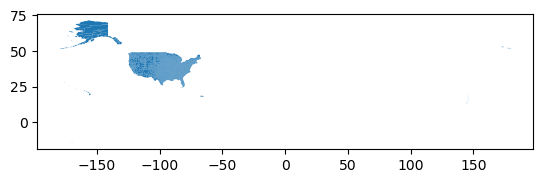

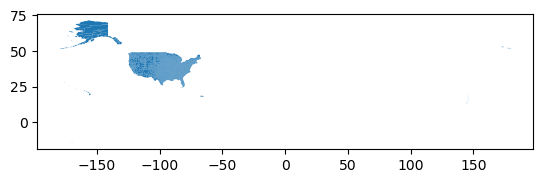

In [26]:
# d
counties.plot()

From the data exploration, we see that the geodataframe mulitple id categorization for each county around the U.S. The columns names are all capitalized except for geometry making the format of the dataframe a little bit inconsistent. The coordinate referencce system is EPSG: 4269 which is standard code for North American Datum 1983. 

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [27]:
# make the columns lowercased
counties.columns = counties.columns.str.lower()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [28]:
# check if New York's state FIPS is in the dataset (36)
counties['statefp'].unique()

array(['12', '06', '18', '35', '10', '48', '30', '42', '72', '47', '29',
       '33', '50', '16', '53', '21', '24', '17', '13', '05', '20', '28',
       '19', '49', '56', '22', '55', '27', '37', '54', '51', '25', '40',
       '31', '41', '01', '04', '32', '39', '38', '26', '36', '23', '08',
       '44', '46', '09', '45', '34', '02', '15', '11', '78', '60', '66',
       '69'], dtype=object)

<Axes: >

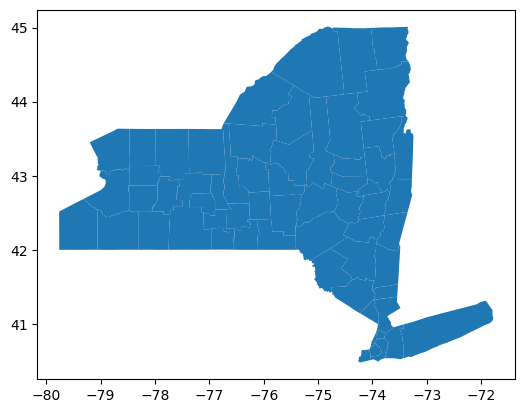

In [29]:
# graph the county boundaries
ny_counties = counties[counties['statefp'] == '36']
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [30]:
ny_counties['name'].unique()

array(['Erie', 'Niagara', 'Jefferson', 'Steuben', 'Seneca', 'Rensselaer',
       'Albany', 'Saratoga', 'Schoharie', 'Schenectady', 'Ulster',
       'Dutchess', 'Orange', 'Columbia', 'Tompkins', 'Tioga', 'Broome',
       'Cayuga', 'Genesee', 'Onondaga', 'Oswego', 'Madison', 'Livingston',
       'Monroe', 'Ontario', 'Orleans', 'Wayne', 'Chautauqua', 'Sullivan',
       'Chemung', 'Cattaraugus', 'Fulton', 'Montgomery', 'Cortland',
       'Warren', 'Washington', 'Otsego', 'Queens', 'Bronx', 'Nassau',
       'Westchester', 'Richmond', 'Kings', 'Suffolk', 'Rockland',
       'New York', 'Putnam', 'Clinton', 'St. Lawrence', 'Herkimer',
       'Oneida', 'Yates', 'Greene', 'Schuyler', 'Delaware', 'Hamilton',
       'Lewis', 'Allegany', 'Chenango', 'Wyoming', 'Franklin', 'Essex'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [31]:
spills_per_county['county'].unique()

array(['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga',
       'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia',
       'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin',
       'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson',
       'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery',
       'Nassau', 'New Jersey - Region 2', 'New York', 'Niagara', 'Oneida',
       'Onondaga', 'Onondaga Indian Reservation', 'Ontario', 'Orange',
       'Orleans', 'Oswego', 'Otsego', 'Pennsylvania - Region 3', 'Putnam',
       'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga',
       'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St Lawrence',
       'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins',
       'Tuscarora Indian Reservation', 'Ulster', 'Warren', 'Washington',
       'Wayne', 'Westchester', 'Wyoming', 'Yates'], dtype=object)

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [32]:
import numpy as np

# check which counties are not in spills_per_county
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name'])
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [33]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [34]:
# check which counties are not in ny_counties
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county'])
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [35]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [36]:
# e. 
# make print statement that shows the number of oil spills in Tuscarora Indian Reservation and Onondaga Indian Reservation?
print(f"There are {spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].iloc[0]} spills in Tuscarora Indian Reservation")
print(f"There are {spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].iloc[0]} spills in Onondaga Indian Reservation")


There are 2 spills in Tuscarora Indian Reservation
There are 1 spills in Onondaga Indian Reservation


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [37]:
# change the name of St Lawrence ot match the name in ny_counties
spills_per_county = spills_per_county.replace({'St Lawrence' : 'St. Lawrence'})

# confirm that the name was changed
assert spills_per_county.loc[spills_per_county['county'] == 'St. Lawrence', 'county'].iloc[0] == 'St. Lawrence'

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [38]:
# a 
# rename the county column to match the column in spills_per_county
ny_counties = ny_counties.rename(columns = {'name' : 'county'})
ny_counties 

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
258,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461..."
259,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."
338,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697..."
352,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999..."
492,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2792,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2829,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508..."
3020,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713..."
3110,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111..."


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [39]:
# join spills_per_county and ny_counties
ny_spills = pd.merge(spills_per_county, ny_counties)
ny_spills

,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
0,Albany,224,36,001,00974099,36001,0500000US36001,Albany County,06,H1,G4020,104,10580,None,A,1354273428,26971923,+42.5882401,-073.9740095,"POLYGON ((-73.96379 42.44162, -73.96666 42.441..."
1,Allegany,32,36,003,00974100,36003,0500000US36003,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2,Bronx,152,36,005,00974101,36005,0500000US36005,Bronx County,06,H6,G4020,408,35620,35614,C,109301867,39287123,+40.8487111,-073.8529390,"POLYGON ((-73.93381 40.88221, -73.93365 40.882..."
3,Broome,80,36,007,00974102,36007,0500000US36007,Broome County,06,H1,G4020,None,13780,None,A,1827626584,25078248,+42.1619773,-075.8302833,"POLYGON ((-75.74223 41.99805, -75.75080 41.997..."
4,Cattaraugus,45,36,009,00974103,36009,0500000US36009,Cattaraugus County,06,H1,G4020,160,36460,None,A,3388177044,36783591,+42.2390986,-078.6623320,"POLYGON ((-78.69725 41.99867, -78.69881 41.998..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,Washington,115,36,115,00974155,36115,0500000US36115,Washington County,06,H1,G4020,104,24020,None,A,2152773131,38123569,+43.3174964,-073.4337096,"POLYGON ((-73.26504 43.10615, -73.26504 43.106..."
58,Wayne,41,36,117,00974156,36117,0500000US36117,Wayne County,06,H1,G4020,464,40380,None,A,1563913363,2018184724,+43.2181139,-077.0494024,"POLYGON ((-76.70573 43.13143, -76.70561 43.129..."
59,Westchester,855,36,119,00974157,36119,0500000US36119,Westchester County,06,H1,G4020,408,35620,35614,A,1115811923,179391712,+41.1526862,-073.7457526,"POLYGON ((-73.65762 40.98550, -73.65739 40.985..."
60,Wyoming,27,36,121,00974158,36121,0500000US36121,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713..."


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [40]:
# check which counties were excluded from the dataset when joining
spills_per_county.loc[~spills_per_county['county'].isin(ny_spills['county'])]

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

It will not affect the map drastically since only 4 different counties were excluded from the dataset. However this missing data show bias in the data as 11 spills will be not be reported and shown in the map. 

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [42]:
ny_spills[ny_spills['county'] == 'Onondaga']

,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
33,Onondaga,214,36,067,00974132,36067,0500000US36067,Onondaga County,06,H1,G4020,532,45060,None,A,2016027811,70512841,+43.0065163,-076.1961336,"POLYGON ((-76.08017 42.78160, -76.08018 42.780..."


In [43]:
ny_spills[ny_spills['county'] == 'Niagara']

,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
31,Niagara,97,36,063,00974130,36063,0500000US36063,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."


In [44]:
# add the number of spillls from Onondaga Indian Reservation to Onondaga
onon_indian_reserve = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].iloc[0]
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += onon_indian_reserve


# add the number of spillls from Tuscarora Indian Reservation to Niagara
tusc_indian_reserve = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].iloc[0]
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += tusc_indian_reserve





In [45]:
ny_spills[ny_spills['county'] == 'Onondaga']

,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
33,Onondaga,215,36,067,00974132,36067,0500000US36067,Onondaga County,06,H1,G4020,532,45060,None,A,2016027811,70512841,+43.0065163,-076.1961336,"POLYGON ((-76.08017 42.78160, -76.08018 42.780..."


In [46]:
ny_spills[ny_spills['county'] == 'Niagara']

,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
31,Niagara,99,36,063,00974130,36063,0500000US36063,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."


In [47]:
# convert ny_spills from pandas data series to a geodataframe
ny_spills = gpd.GeoDataFrame(
    ny_spills,
    geometry='geometry',
    crs=ny_counties.crs
)

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



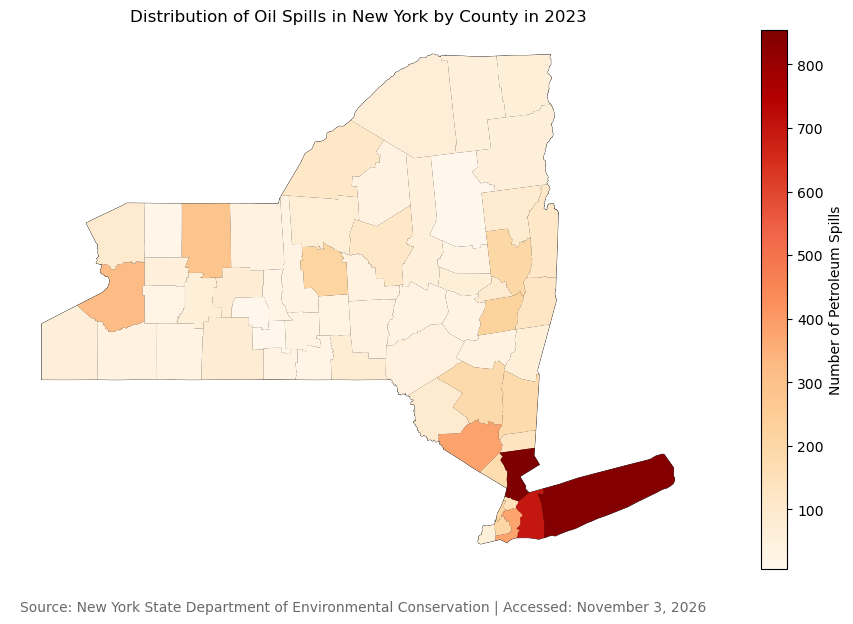

In [48]:
fig, ax = plt.subplots(figsize = (14, 7))

# plot New York county boundaries 
ny_counties.plot(
    ax = ax,
    facecolor='lightgray',
    edgecolor='black',
    linewidth=0.5
)

# plot oil spills values 
ny_spills.plot(
    ax=ax,
    column='n_spills',
    cmap='OrRd',
    legend=True,
    legend_kwds = {'label' : "Number of Petroleum Spills"}
)
ax.set_title('Distribution of Oil Spills in New York by County in 2023')
ax.set_axis_off()

# add text that sources the dataset
fig.text(
    0.5, 0.05,
    'Source: New York State Department of Environmental Conservation | Accessed: November 3, 2026',
    ha='center',
    fontsize=10,
    color='dimgray'
)

plt.show()


b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

The choropleth map was created by taking an online dataset of all recorded substance spillage across the U.S. and filtering the data down to petroleum spills in New York in 2023. After the filtering and cleaning process, we merged an New York counties dataset with the spill dataset in order to map the distribution of petroleum spills across each county in New York. However when merging, one issue we ran into was that two counties the Tuscarora and Onondaga Indian Reservations were excluded. To resolve this issue and insure that our map is as accurate as possible, we took the number of spills from Onondaga and Tuscarora Indian Reservations and integrated the values into Onondaga and Niagara county respectively. By doing this, we preserve the integrity of indigenous communities through the CARE principles. 

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.